---
embed-resources: True
format:
    html:
        page-layout: full
        fontsize: 18px

title: 'EDA Forecasting LANCS'
warning: False
toc: False
---

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MultipleLocator

def k_units(value, _pos):
    scaled = value / 1_000
    if scaled == 0:
        return "0"
    if float(scaled).is_integer():
        return f"{int(scaled)}k"
    return f"{scaled:.1f}k"

In [13]:
# Load data
cola_task1 = pd.read_csv("data/brightfuture_cola_task1_groupB.csv")

# Project overview

* Customer: BrightFuture Beverages
* Mid-sized UK soft-drinkss brand
* sells through supermarkets

Encargados que necesitan ayuda:
* Head of marketing
* Supply planner

Los resultados van en una presentación

## Task 1: Forecast for one product

* Next quarter promotions are being built.
* They need weekly unit demand forecasts for the next 13 weeks

Decisions:
* Which week to promote
* agree volumes with supply chain so promoted weeks dont run out of stock.

questions:

* How many units are the expected demand?
* How far off could these numbers be?
* Can you also produce the demand forecasts when there are no promotions and no discounts as a pesimistic scenario?
* Compare promotional scenario vs the worst one.
* Suggest a potential improvement for the plan
* Business owner report, no math, just to defend to the commercial director

### Units sold over time

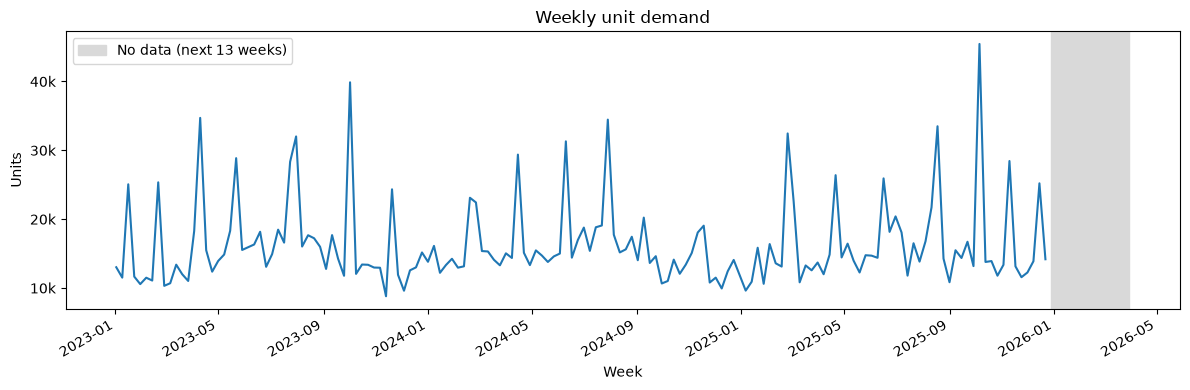

In [14]:
weeks = pd.to_datetime(cola_task1["week"])
missing = cola_task1["units"].isna()
forecast_start = weeks[missing].min()
forecast_end = weeks[missing].max() + pd.Timedelta(days=7)

fig, ax = plt.subplots(figsize=(12, 4))
ax.axvspan(forecast_start, forecast_end, color="0.85", label="No data (next 13 weeks)", zorder=0)
ax.plot(weeks, cola_task1["units"], zorder=1)
ax.set_xlabel("Week")
ax.set_ylabel("Units")
ax.yaxis.set_major_locator(MultipleLocator(10_000))
ax.yaxis.set_major_formatter(FuncFormatter(k_units))
ax.set_title("Weekly unit demand")
ax.legend(loc="upper left")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### Units sold over time + events

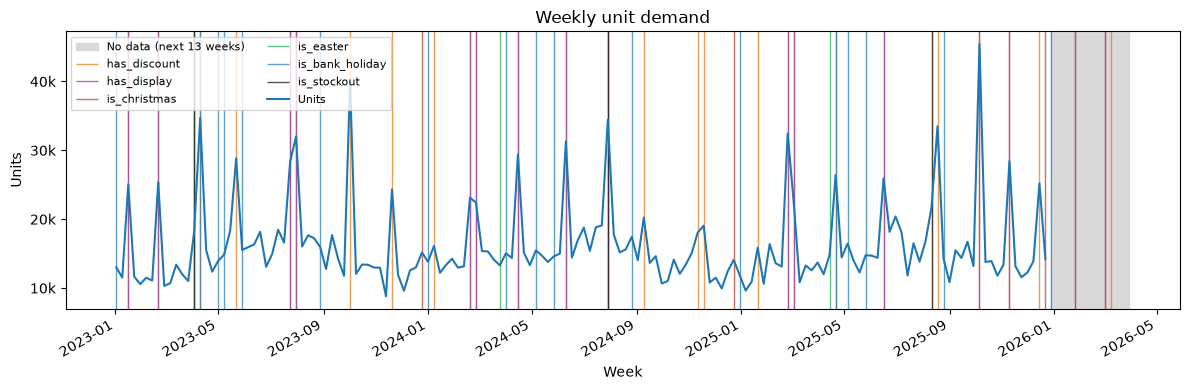

In [16]:
weeks = pd.to_datetime(cola_task1["week"])
missing = cola_task1["units"].isna()
forecast_start = weeks[missing].min()
forecast_end = weeks[missing].max() + pd.Timedelta(days=7)

events = {
    "has_discount": (cola_task1["discount_pct"] > 0, "#e67e22"),
    "has_display": (cola_task1["display"] == 1, "#8e44ad"),
    "is_christmas": (cola_task1["christmas"] == 1, "#c0392b"),
    "is_easter": (cola_task1["easter"] == 1, "#27ae60"),
    "is_bank_holiday": (cola_task1["bank_holiday"] == 1, "#2980b9"),
    "is_stockout": (cola_task1["stockout"] == 1, "#1a1a1a"),
}

fig, ax = plt.subplots(figsize=(12, 4))
ax.axvspan(forecast_start, forecast_end, color="0.85", label="No data (next 13 weeks)", zorder=0)
for name, (mask, color) in events.items():
    event_weeks = weeks[mask]
    ax.vlines(event_weeks, ymin=0, ymax=1, transform=ax.get_xaxis_transform(), color=color, alpha=0.75, linewidth=1, label=name, zorder=1)
ax.plot(weeks, cola_task1["units"], color="C0", zorder=2, label="Units")
ax.set_xlabel("Week")
ax.set_ylabel("Units")
ax.yaxis.set_major_locator(MultipleLocator(10_000))
ax.yaxis.set_major_formatter(FuncFormatter(k_units))
ax.set_title("Weekly unit demand")
ax.legend(loc="upper left", ncol=2, fontsize=8)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### Units sold distribution per event type

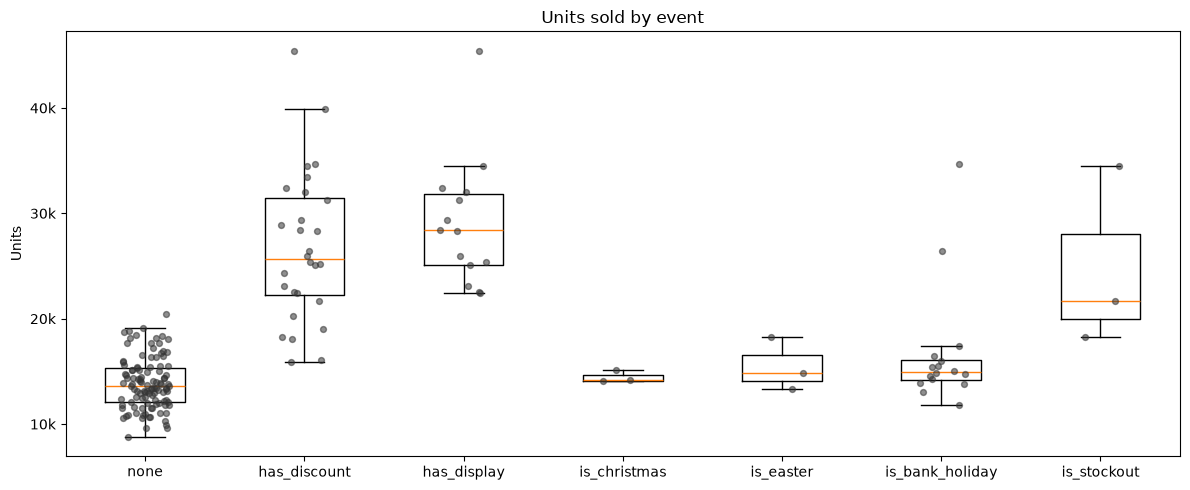

In [17]:
observed = cola_task1.dropna(subset=["units"])
groups = {
    "none": (
        (observed["discount_pct"] == 0)
        & (observed["display"] == 0)
        & (observed["christmas"] == 0)
        & (observed["easter"] == 0)
        & (observed["bank_holiday"] == 0)
        & (observed["stockout"] == 0)
    ),
    "has_discount": observed["discount_pct"] > 0,
    "has_display": observed["display"] == 1,
    "is_christmas": observed["christmas"] == 1,
    "is_easter": observed["easter"] == 1,
    "is_bank_holiday": observed["bank_holiday"] == 1,
    "is_stockout": observed["stockout"] == 1,
}
labels = list(groups)
values = [observed.loc[mask, "units"].to_numpy() for mask in groups.values()]

fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot(values, tick_labels=labels, showfliers=False)
rng = np.random.default_rng(0)
for i, units in enumerate(values, start=1):
    jitter = rng.uniform(-0.15, 0.15, size=len(units))
    ax.scatter(np.full(len(units), i) + jitter, units, s=18, alpha=0.55, color="0.2", zorder=3)
ax.set_ylabel("Units")
ax.yaxis.set_major_locator(MultipleLocator(10_000))
ax.yaxis.set_major_formatter(FuncFormatter(k_units))
ax.set_title("Units sold by event")
plt.tight_layout()
plt.show()